# Aurisign FIlipino Sign Language Gesture Recognition 1D CNN Numbers Training

## Dependency Installation and Imports

In [1]:
!pip install opencv-python mediapipe==0.10.14 matplotlib seaborn tensorflow scikit-learn tensorflowjs


[notice] A new release of pip is available: 26.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [2]:
# %%
import cv2
import mediapipe as mp
import numpy as np
import os
from time import time

2026-10-27 16:08:32.225698: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-27 16:08:32.231103: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-27 16:08:32.250653: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793088512.282560   60326 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793088512.292185   60326 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793088512.314471   60326 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linkin

### Data Collection

In [ ]:
# %%
# Record 24-frame sequences for each supported class and diverse unsupported gestures for NONE.
# For NONE, vary poses, movement, backgrounds, and people; do not record a supported sign as NONE.
# Press "c" to record one full sequence for the current letter, "q" to move to the next letter.
MOTION_CLASSES = ["0", "1", "2", "3", "4", "5", "6", "7", "8", "9", "10", "NONE"]   # full set — used everywhere downstream

MOTION_DATA_PATH = "number_dataset"
SEQ_LEN = 24                 # ~0.8-1s of motion at a typical webcam framerate
ADDITIONAL_SAMPLES_PER_GESTURE = 200  # keeps existing files and records this many more
CENTER_BY_WRIST = True
INCLUDE_HANDEDNESS = True
NUM_FEATURES = 64 if INCLUDE_HANDEDNESS else 63

os.makedirs(MOTION_DATA_PATH, exist_ok=True)
for g in MOTION_CLASSES:
    os.makedirs(os.path.join(MOTION_DATA_PATH, g), exist_ok=True)

mp_hands = mp.solutions.hands
mp_draw  = mp.solutions.drawing_utils
hands = mp_hands.Hands(static_image_mode=False, max_num_hands=1,
                       min_detection_confidence=0.7, min_tracking_confidence=0.7)

cap = cv2.VideoCapture(0)

def get_frame_keypoints(frame):
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    result = hands.process(rgb)
    if not result.multi_hand_landmarks:
        return None, frame
    lm = result.multi_hand_landmarks[0]
    mp_draw.draw_landmarks(frame, lm, mp_hands.HAND_CONNECTIONS)
    pts = np.array([[p.x, p.y, p.z] for p in lm.landmark])
    if CENTER_BY_WRIST:
        pts -= pts[0]
    pts = pts.flatten()
    if INCLUDE_HANDEDNESS and result.multi_handedness:
        hl = result.multi_handedness[0].classification[0].label
        pts = np.append(pts, 0 if hl == "Left" else 1)
    return pts, frame

for gesture in MOTION_CLASSES:
    print(f"Collecting motion: {gesture} — [c]=record one {SEQ_LEN}-frame sequence, [q]=next letter")
    existing = [int(os.path.splitext(f)[0]) for f in os.listdir(os.path.join(MOTION_DATA_PATH, gesture))
                if f.endswith(".npy") and os.path.splitext(f)[0].isdigit()]
    count = max(existing, default=-1) + 1
    target = count + ADDITIONAL_SAMPLES_PER_GESTURE
    while count < target:
        ret, frame = cap.read()
        if not ret:
            continue
        frame = cv2.flip(frame, 1)
        _, frame = get_frame_keypoints(frame.copy())
        cv2.putText(frame, f"{gesture} {count}/{target}  [c]=record  [q]=next",
                    (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
        cv2.imshow("Collect Motion Gestures", frame)
        k = cv2.waitKey(1) & 0xFF

        if k == ord("c"):
            sequence = []
            print(f"  Recording {gesture} #{count}... perform the gesture now")
            while len(sequence) < SEQ_LEN:
                ret, f2 = cap.read()
                if not ret:
                    continue
                f2 = cv2.flip(f2, 1)
                kp, f2 = get_frame_keypoints(f2)
                # a short mid-gesture occlusion shouldn't corrupt the whole window,
                # so hold the last known keypoints instead of dropping the frame
                if kp is None and sequence:
                    kp = sequence[-1]
                elif kp is None:
                    kp = np.zeros(NUM_FEATURES)
                sequence.append(kp)
                cv2.putText(f2, f"RECORDING {len(sequence)}/{SEQ_LEN}", (10, 30),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)
                cv2.imshow("Collect Motion Gestures", f2)
                cv2.waitKey(1)
            np.save(os.path.join(MOTION_DATA_PATH, gesture, f"{count:03d}.npy"), np.array(sequence))
            count += 1

        if k == ord("q"):
            break

cap.release()
cv2.destroyAllWindows()
print("Done collecting motion gestures!")

### Number Data Loading and Preprocessing

In [30]:
# Landmark normalization: wrist-relative position is already applied during collection.
# This second step normalizes scale using wrist-to-middle-MCP distance per hand/frame.
# Keep this exact transform consistent for training, validation, test, and live inference.
def normalize_landmark_sequences(X, hand_feature_width=64):
    """Scale-normalize wrist-centered MediaPipe xyz coordinates per hand/frame.

    Each hand's xyz coordinates are divided by its wrist-to-middle-MCP distance
    (landmark 0 to landmark 9). The handedness feature at index 63 is preserved.
    Zero-padded/missing hands remain zero. Input shape: (samples, frames, features).
    """
    X = np.asarray(X, dtype=np.float32).copy()
    for start in range(0, X.shape[-1], hand_feature_width):
        block_end = min(start + hand_feature_width, X.shape[-1])
        xyz_end = min(start + 63, block_end)
        if xyz_end - start < 30:
            continue
        xyz = X[..., start:xyz_end].reshape(*X.shape[:-1], -1, 3)
        # Wrist is already at/near (0, 0, 0) after wrist-centering.
        # Landmark 9 (middle-finger MCP) is xyz index 27:30.
        palm_scale = np.linalg.norm(xyz[..., 9, :], axis=-1, keepdims=True)
        valid_hand = palm_scale > 1e-6
        safe_scale = np.where(valid_hand, palm_scale, 1.0)
        normalized_xyz = xyz / safe_scale[..., None]
        normalized_xyz = np.where(valid_hand[..., None], normalized_xyz, 0.0)
        X[..., start:xyz_end] = normalized_xyz.reshape(*X.shape[:-1], -1)
    return X


In [31]:
# Load saved 24-frame sequences; use stratification to preserve each class in both splits.
import tensorflow as tf
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split

X_motion, y_indices = [], []
for i, gesture in enumerate(MOTION_CLASSES):
    folder = os.path.join(MOTION_DATA_PATH, gesture)
    paths = sorted(f for f in os.listdir(folder) if f.lower().endswith('.npy'))
    if not paths:
        raise ValueError(f"No .npy samples for {gesture}. Record examples before training.")
    for f in paths:
        sample = np.load(os.path.join(folder, f), allow_pickle=False)
        if sample.shape != (SEQ_LEN, NUM_FEATURES) or not np.isfinite(sample).all():
            raise ValueError(f"Invalid sequence {gesture}/{f}: shape {sample.shape}")
        X_motion.append(sample)
        y_indices.append(i)

X_motion = np.asarray(X_motion, dtype=np.float32)
y_indices = np.asarray(y_indices, dtype=np.int64)
X_motion = normalize_landmark_sequences(X_motion, hand_feature_width=NUM_FEATURES)
counts = np.bincount(y_indices, minlength=len(MOTION_CLASSES))
print('Samples per class:', dict(zip(MOTION_CLASSES, counts.tolist())))
if counts.min() < 3:
    raise ValueError('Collect at least 3 samples per class; preferably many more.')

# Separate held-out test data. Validation data comes ONLY from the training partition.
X_train_all, Xm_test, y_train_all, y_test_idx = train_test_split(
    X_motion, y_indices, test_size=0.20, random_state=42, stratify=y_indices)
Xm_train, Xm_val, y_train_idx, y_val_idx = train_test_split(
    X_train_all, y_train_all, test_size=0.20, random_state=42, stratify=y_train_all)
ym_train = to_categorical(y_train_idx, num_classes=len(MOTION_CLASSES))
ym_val = to_categorical(y_val_idx, num_classes=len(MOTION_CLASSES))
ym_test = to_categorical(y_test_idx, num_classes=len(MOTION_CLASSES))
print('Train:', Xm_train.shape, 'Validation:', Xm_val.shape, 'Test:', Xm_test.shape)
# IMPORTANT: If consecutive recordings are nearly identical, random splitting may inflate scores.
# For stronger evidence, hold out entire recording sessions or participants for final testing.


Samples per class: {'0': 200, '1': 200, '2': 200, '3': 200, '4': 200, '5': 200, '6': 200, '7': 200, '8': 200, '9': 200, '10': 200, 'NONE': 200}
Train: (1536, 24, 64) Validation: (384, 24, 64) Test: (480, 24, 64)


### Number Model

In [32]:
# %%
motion_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(SEQ_LEN, X_motion.shape[-1])),
    tf.keras.layers.Conv1D(64, 3, activation='relu', padding='same'),
    tf.keras.layers.Conv1D(64, 3, activation='relu', padding='same'),
    tf.keras.layers.GlobalAveragePooling1D(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(len(MOTION_CLASSES), activation='softmax'),
])
motion_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
motion_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_8 (Conv1D)               │ (None, 24, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_9 (Conv1D)               │ (None, 24, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_4      │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 12)             │           780 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,644 (115.80 KB)

 Trainable params: 29,644 (115.80 KB)

 Non-trainable params: 0 (0.00 B)

### Number Model Training

In [33]:
# Validation is used for model selection; the test set is reserved for final evaluation.
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
]
motion_history = motion_model.fit(
    Xm_train, ym_train, validation_data=(Xm_val, ym_val),
    epochs=50, batch_size=8, callbacks=callbacks)


Epoch 1/50
192/192 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4043 - loss: 1.7261 - val_accuracy: 0.7344 - val_loss: 0.8579
Epoch 2/50
192/192 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7546 - loss: 0.6556 - val_accuracy: 0.8438 - val_loss: 0.4169
Epoch 3/50
192/192 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8763 - loss: 0.3524 - val_accuracy: 0.9505 - val_loss: 0.2170
Epoch 4/50
192/192 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9349 - loss: 0.2002 - val_accuracy: 0.9740 - val_loss: 0.1229
Epoch 5/50
192/192 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9688 - loss: 0.1193 - val_accuracy: 0.9844 - val_loss: 0.0876
Epoch 6/50
192/192 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9661 - loss: 0.1069 - val_accuracy: 0.9714 - val_loss: 0.1017
Epoch 7/50
192/192 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9779 - loss: 0.0747 - val_accuracy: 0.9792 - val_loss: 0.1125
Epoch 8/50
192/192 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9811 - loss: 0.0665 - val_accuracy: 0.

### Training vs Validation Loss and Accuracy

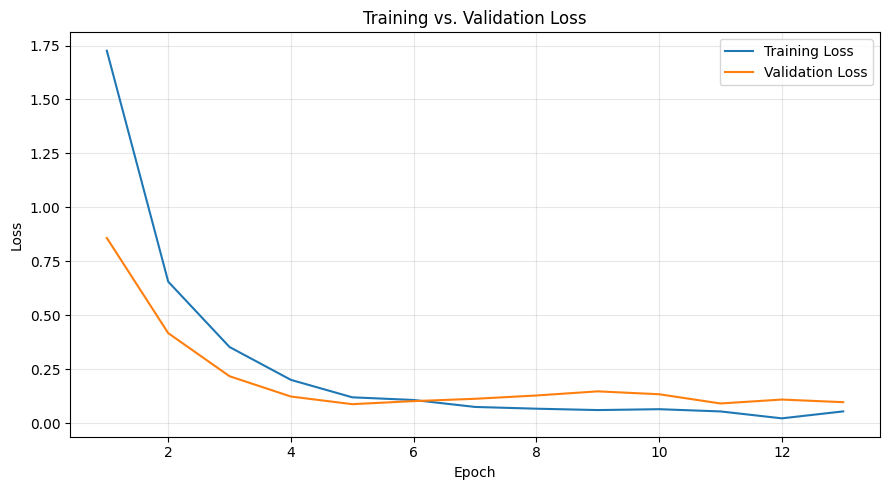

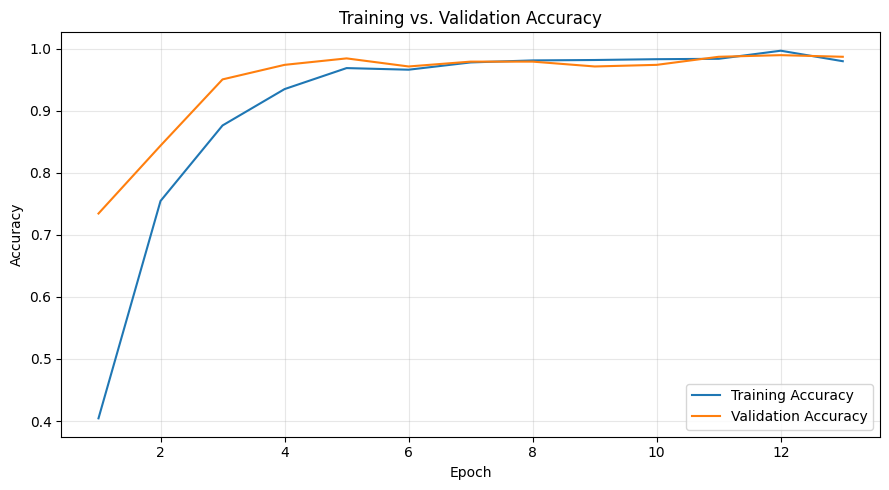

In [34]:
import matplotlib.pyplot as plt

# Use the History object returned by TensorFlow/Keras model.fit()
history_data = motion_history.history

epochs = range(1, len(history_data["loss"]) + 1)

# 1. Loss curve — useful for diagnosing overfitting/underfitting
plt.figure(figsize=(9, 5))
plt.plot(epochs, history_data["loss"], label="Training Loss")
plt.plot(epochs, history_data["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs. Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Accuracy curve
if "accuracy" in history_data and "val_accuracy" in history_data:
    plt.figure(figsize=(9, 5))
    plt.plot(epochs, history_data["accuracy"], label="Training Accuracy")
    plt.plot(epochs, history_data["val_accuracy"], label="Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title("Training vs. Validation Accuracy")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

### Held-out Evaluation: Accuracy, Precision, Recall, F1-score, Confusion Matrix, and Inference Time

=== HELD-OUT TEST METRICS ===
Test samples       : 480
Accuracy           : 0.9854
Macro precision    : 0.9853
Macro recall       : 0.9854
Macro F1-score     : 0.9852
Weighted precision : 0.9853
Weighted recall    : 0.9854
Weighted F1-score  : 0.9852

Per-class classification report:
              precision    recall  f1-score   support

           0     0.9500    0.9500    0.9500        40
           1     1.0000    1.0000    1.0000        40
           2     1.0000    1.0000    1.0000        40
           3     1.0000    1.0000    1.0000        40
           4     1.0000    1.0000    1.0000        40
           5     0.9524    1.0000    0.9756        40
           6     1.0000    1.0000    1.0000        40
           7     1.0000    1.0000    1.0000        40
           8     1.0000    1.0000    1.0000        40
           9     1.0000    1.0000    1.0000        40
          10     0.9756    1.0000    0.9877        40
        NONE     0.9459    0.8750    0.9091        40

    accurac

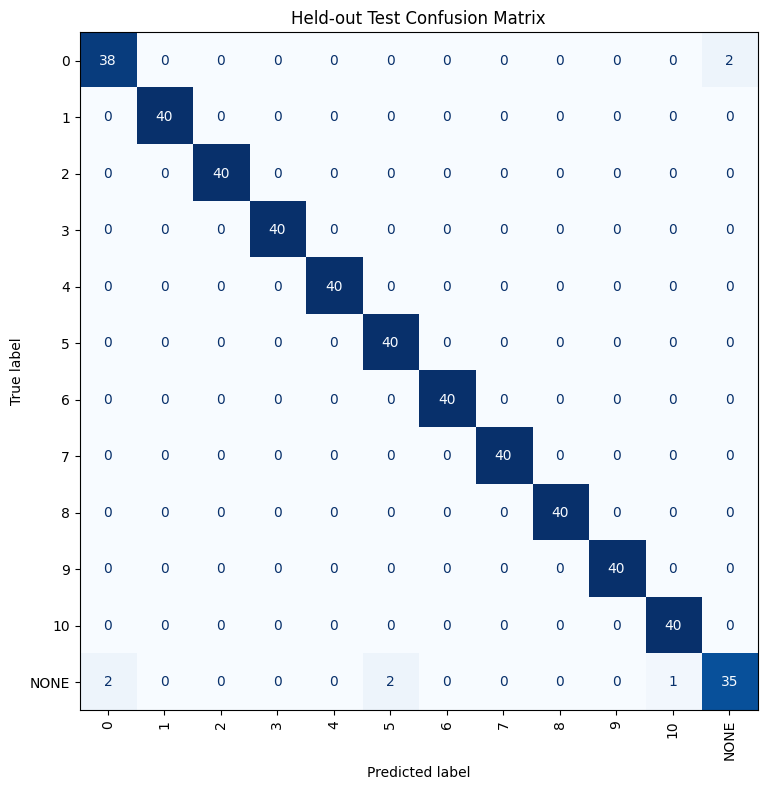


=== MODEL-ONLY INFERENCE TIME ===
Mean latency       : 5.473 ms
Median latency     : 5.241 ms
95th percentile    : 6.585 ms
Minimum latency    : 4.883 ms
Maximum latency    : 9.154 ms
Note: timing covers the model prediction on an already-prepared sequence; it excludes camera capture and MediaPipe.


In [35]:
# Held-out test evaluation: classification metrics, confusion matrix, and model-only inference time.
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

# Use the matching variables defined by the notebook.
# Alphabet/number notebooks use Xm_test and y_test_idx; phrase notebook uses X_test and y_true_idx.
if "Xm_test" in globals():
    X_eval = Xm_test
    y_true_eval = y_test_idx
    eval_model = motion_model
    labels_eval = MOTION_CLASSES
elif "X_test_seq" in globals():
    X_eval = X_test_seq
    y_true_eval = y_test_idx
    eval_model = model
    labels_eval = PHRASE_CLASSES
else:
    raise NameError("Expected held-out test arrays are not available. Run the data-splitting cells first.")

# Warm-up calls reduce one-time tracing/initialization effects on latency.
_ = eval_model(X_eval[:1], training=False)
for _ in range(5):
    _ = eval_model(X_eval[:1], training=False)

# Batch predictions for classification metrics.
probabilities = np.asarray(eval_model.predict(X_eval, verbose=0))
y_pred_eval = np.argmax(probabilities, axis=1)

print("=== HELD-OUT TEST METRICS ===")
print(f"Test samples       : {len(y_true_eval)}")
print(f"Accuracy           : {accuracy_score(y_true_eval, y_pred_eval):.4f}")
print(f"Macro precision    : {precision_score(y_true_eval, y_pred_eval, average='macro', zero_division=0):.4f}")
print(f"Macro recall       : {recall_score(y_true_eval, y_pred_eval, average='macro', zero_division=0):.4f}")
print(f"Macro F1-score     : {f1_score(y_true_eval, y_pred_eval, average='macro', zero_division=0):.4f}")
print(f"Weighted precision : {precision_score(y_true_eval, y_pred_eval, average='weighted', zero_division=0):.4f}")
print(f"Weighted recall    : {recall_score(y_true_eval, y_pred_eval, average='weighted', zero_division=0):.4f}")
print(f"Weighted F1-score  : {f1_score(y_true_eval, y_pred_eval, average='weighted', zero_division=0):.4f}")
print("\nPer-class classification report:")
print(classification_report(
    y_true_eval, y_pred_eval, labels=np.arange(len(labels_eval)),
    target_names=labels_eval, digits=4, zero_division=0
))

# Confusion matrix.
cm = confusion_matrix(y_true_eval, y_pred_eval, labels=np.arange(len(labels_eval)))
fig, ax = plt.subplots(figsize=(max(10, len(labels_eval) * 0.55), max(8, len(labels_eval) * 0.5)))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels_eval)
disp.plot(ax=ax, xticks_rotation=90, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Held-out Test Confusion Matrix")
plt.tight_layout()
plt.show()

# Single-sample model inference latency (preprocessed landmark sequence -> prediction).
# This excludes camera capture and MediaPipe landmark extraction.
latency_ms = []
for sample in X_eval:
    sample_batch = np.expand_dims(sample.astype(np.float32), axis=0)
    start = time.perf_counter()
    _ = eval_model(sample_batch, training=False)
    latency_ms.append((time.perf_counter() - start) * 1000.0)

latency_ms = np.asarray(latency_ms)
print("\n=== MODEL-ONLY INFERENCE TIME ===")
print(f"Mean latency       : {latency_ms.mean():.3f} ms")
print(f"Median latency     : {np.percentile(latency_ms, 50):.3f} ms")
print(f"95th percentile    : {np.percentile(latency_ms, 95):.3f} ms")
print(f"Minimum latency    : {latency_ms.min():.3f} ms")
print(f"Maximum latency    : {latency_ms.max():.3f} ms")
print("Note: timing covers the model prediction on an already-prepared sequence; it excludes camera capture and MediaPipe.")


### Number Model Export

In [36]:
# %%
motion_model.export("number_model")
print("Number SavedModel export complete!")

# In Google Colab, convert this the same way you convert the static model,
# just pointed at the motion folders so it doesn't overwrite the static tfjs export:
# !tensorflowjs_converter --input_format=tf_saved_model --output_format=tfjs_graph_model number_model tfjs_number_model
# Export class order for web/mobile inference; the last output is NONE.
import json
with open("number_labels.json", "w", encoding="utf-8") as file:
    json.dump(MOTION_CLASSES, file, ensure_ascii=False, indent=2)
print('Exported labels:', MOTION_CLASSES)


INFO:tensorflow:Assets written to: number_model/assets


INFO:tensorflow:Assets written to: number_model/assets


Saved artifact at 'number_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 24, 64), dtype=tf.float32, name='keras_tensor_28')
Output Type:
  TensorSpec(shape=(None, 12), dtype=tf.float32, name=None)
Captures:
  128007742866448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  128007742871056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  128007742866832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  128007742871632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  128007742874704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  128007742874320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  128006470524880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  128006470532176: TensorSpec(shape=(), dtype=tf.resource, name=None)
Number SavedModel export complete!
Exported labels: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', 'NONE']
